# Notebook 06: Predictive Classification - Decision Tree
## Educational Classification of Recorded Arrest Outcomes
**Author:** Data Science & Crime Analytics Team

### Problem Formulation:
Predict the recorded arrest outcome (`ArrestFlag` = 0 or 1) for a reported incident using non-sensitive contextual incident attributes. This classification is conducted strictly as an educational machine-learning exercise.

### Class Imbalance Handling:
The empirical arrest rate is 14.94% (74,379 arrests vs. 423,540 non-arrests). A naive classifier predicting 'No Arrest' achieves **85.06% accuracy** but has a **Recall of 0.0**. To prevent majority-class collapse, the model is trained with `class_weight='balanced'`.

In [1]:
import os
import psycopg2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

DB_PARAMS = {'host': 'localhost', 'port': 5432, 'user': 'postgres', 'password': 'root', 'dbname': 'chicago_crime_dw'}
conn = psycopg2.connect(**DB_PARAMS)
sql = '''
SELECT PrimaryType, LocationGroup, District, Hour, DayOfWeek, IsWeekend, DomesticFlag, IsNightIncident, ArrestFlag, Date
FROM mart.PublicSafetyAnalyticsMart;
'''
df = pd.read_sql(sql, conn)
conn.close()
print(f'Loaded {len(df):,} records for Decision Tree training.')

C:\Users\gsand\AppData\Local\Temp\ipykernel_123788\73441663.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(sql, conn)


Loaded 497,919 records for Decision Tree training.


### 1. Test Set Performance Metrics

In [2]:
dt_metrics = pd.read_csv('../outputs/results/decision_tree_metrics.csv')
dt_metrics

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,TrueNegatives,FalsePositives,FalseNegatives,TruePositives
0,"DecisionTreeClassifier (Pruned depth=5, Balanced)",0.7718,0.3464,0.5559,0.4268,0.7392,53300,12443,5267,6594


### 2. Feature Importance Breakdown

In [3]:
feat_imp = pd.read_csv('../outputs/tables/decision_tree_feature_importance.csv')
feat_imp.head(10)

,Feature,Importance
0,primarytype_NARCOTICS,0.402385
1,primarytype_WEAPONS VIOLATION,0.281120
2,primarytype_OTHER OFFENSE,0.112333
3,primarytype_BATTERY,0.086652
4,locationgroup_Residential,0.073662
5,domesticflag,0.035701
6,hour,0.005258
7,locationgroup_Public Facility / Institution,0.002116
8,district_4,0.000554
9,district_18,0.000116


### 3. Tree Structure, Confusion Matrix, and ROC Curve

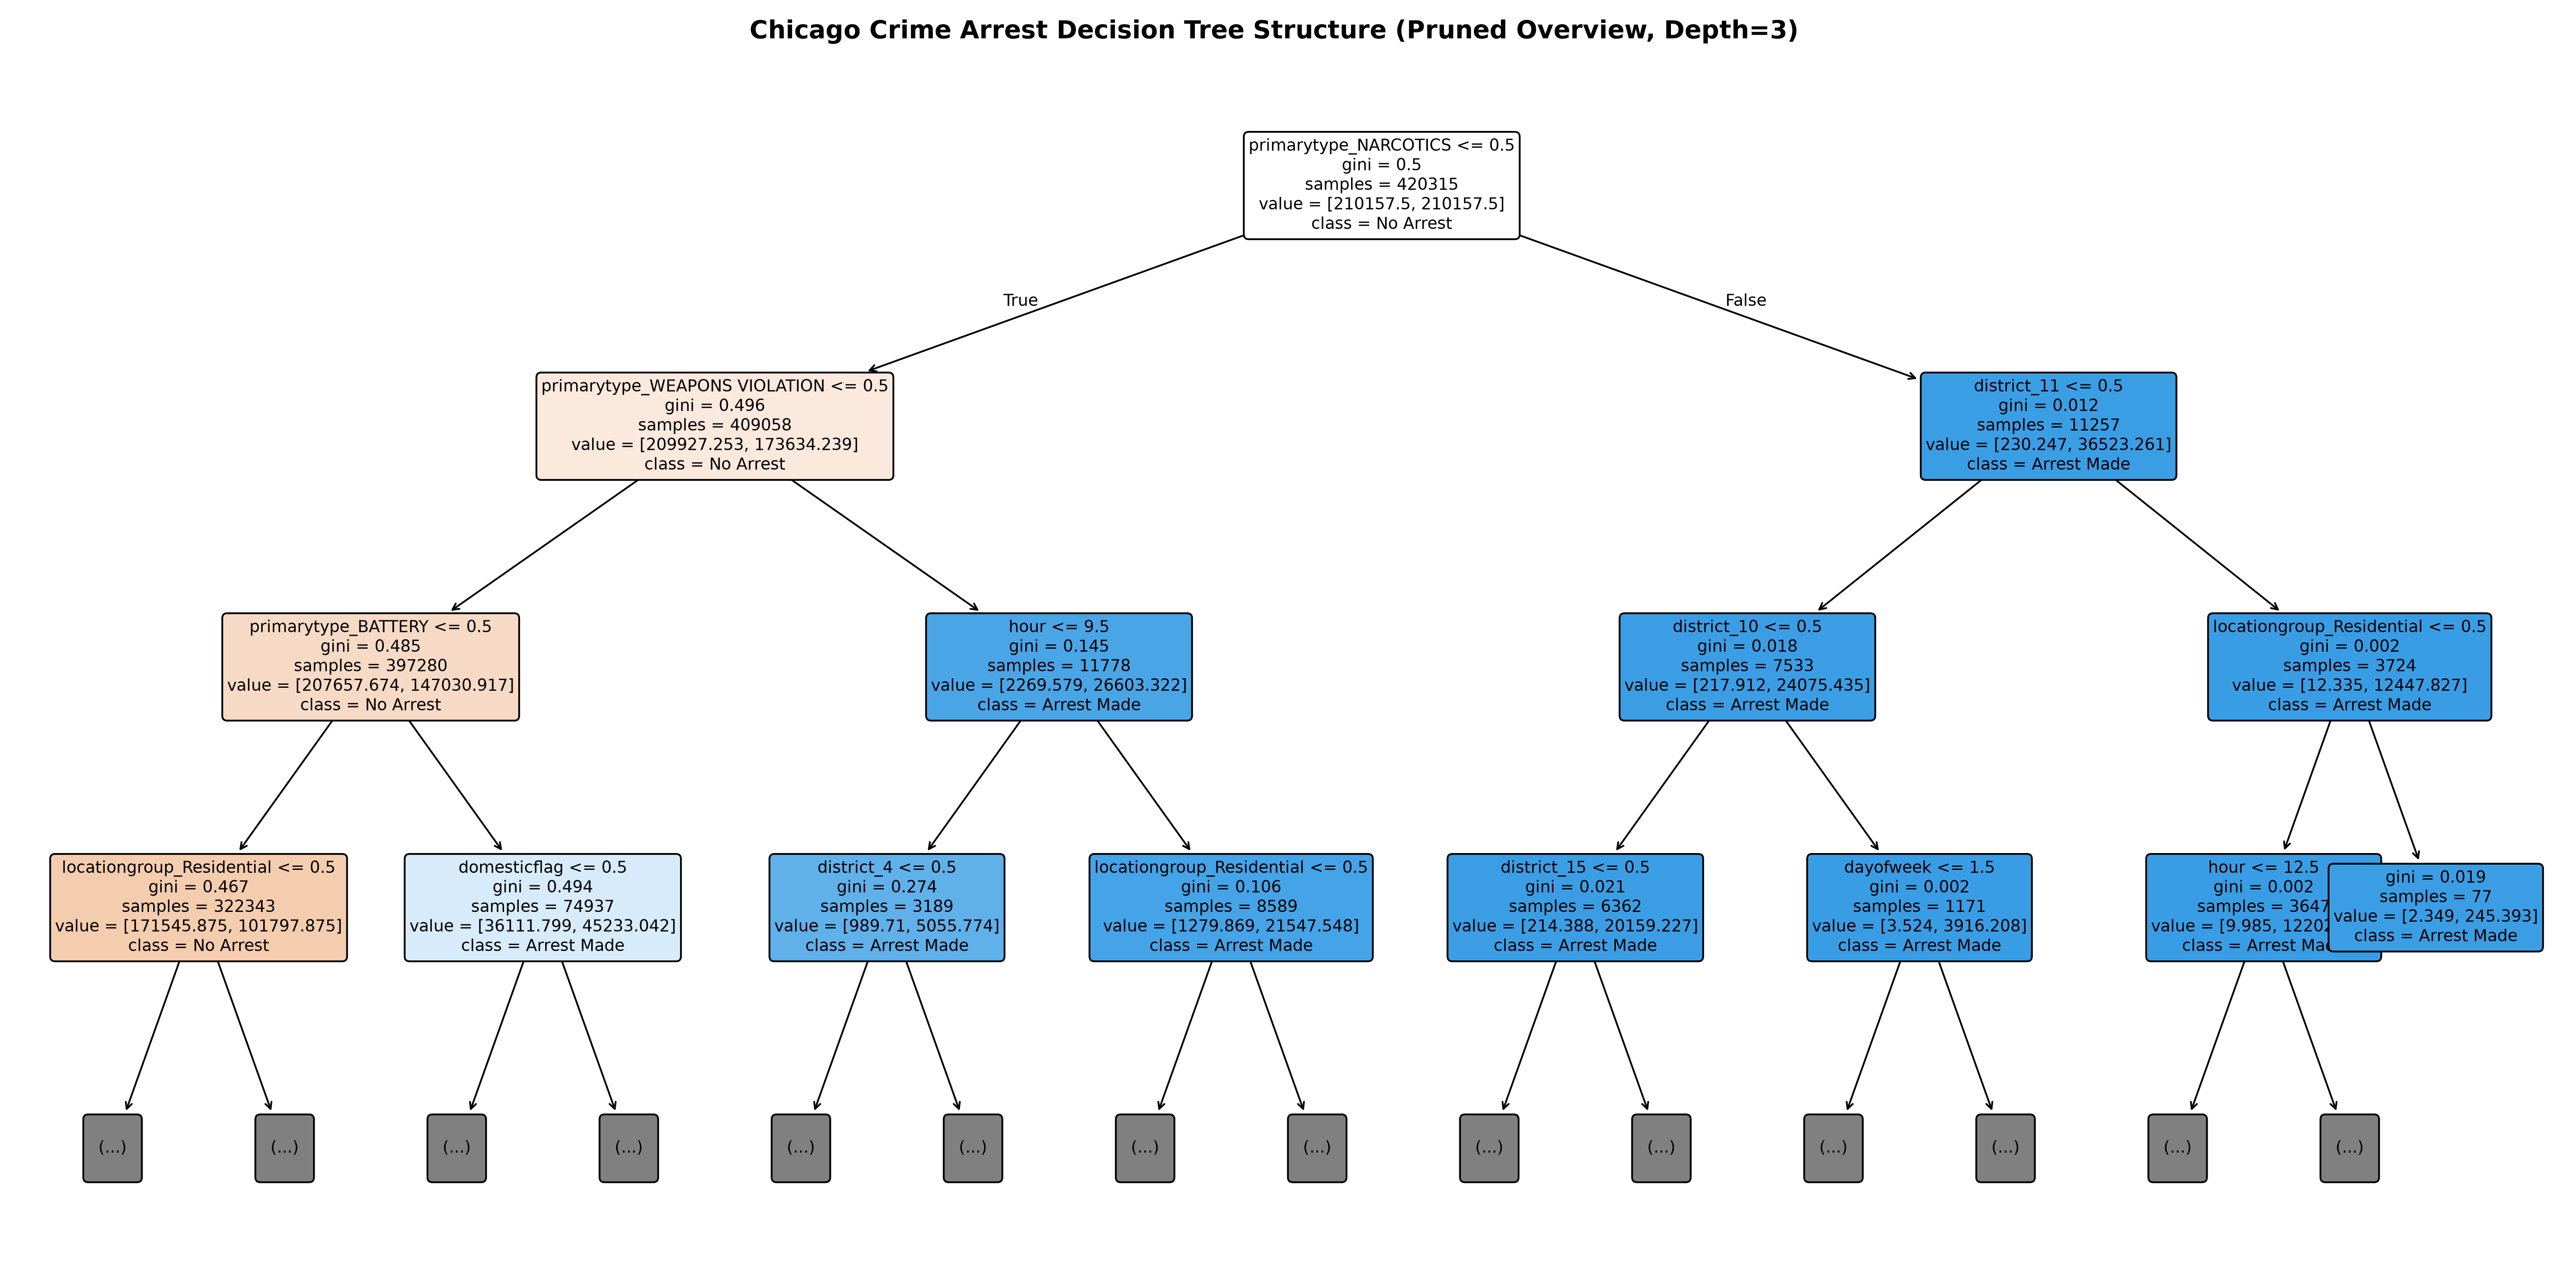

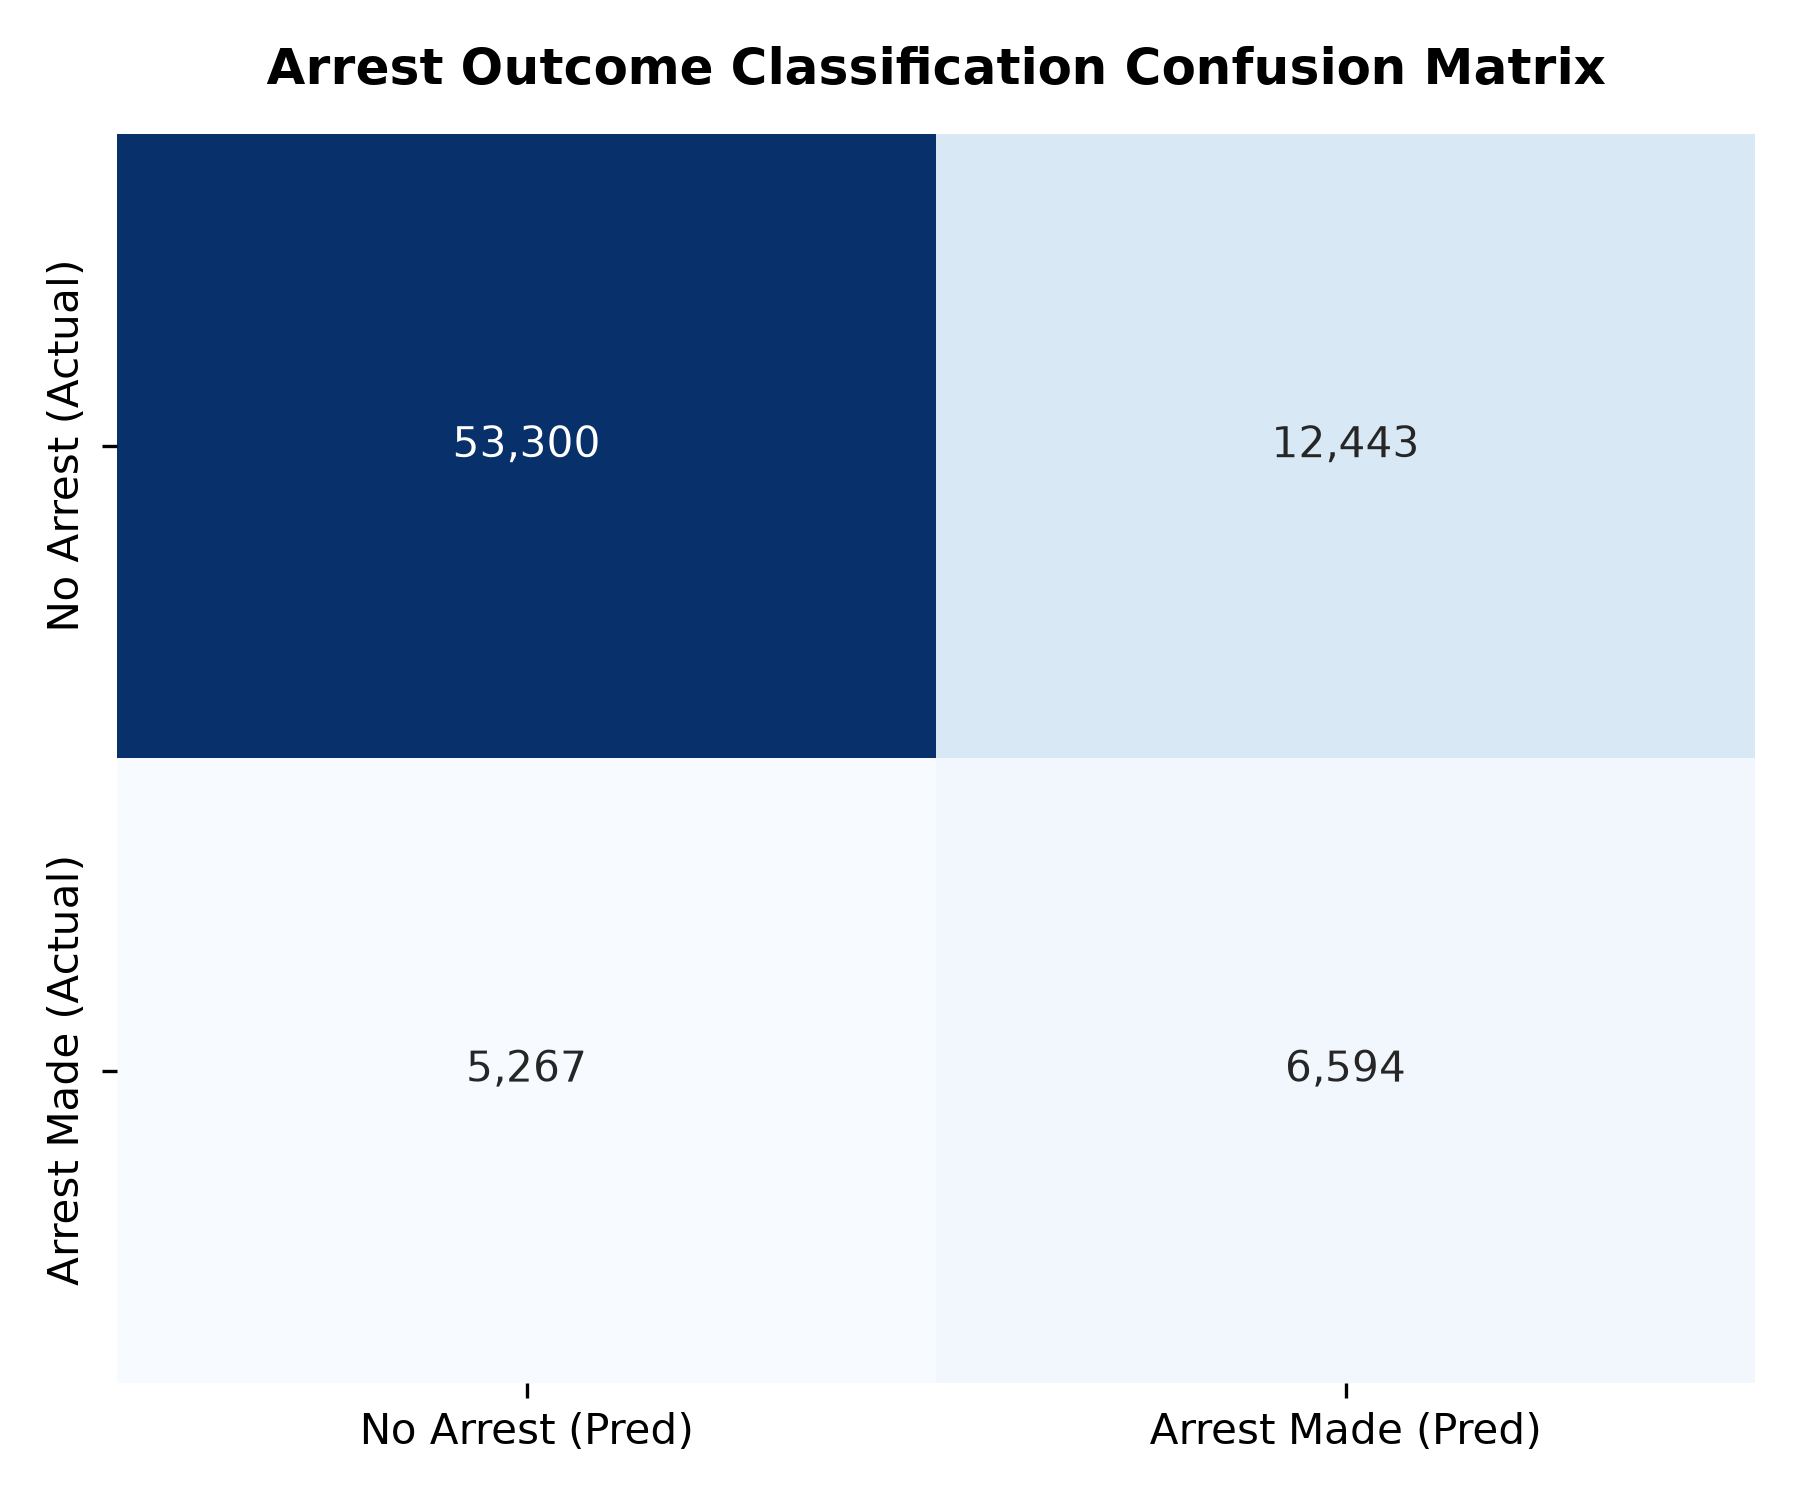

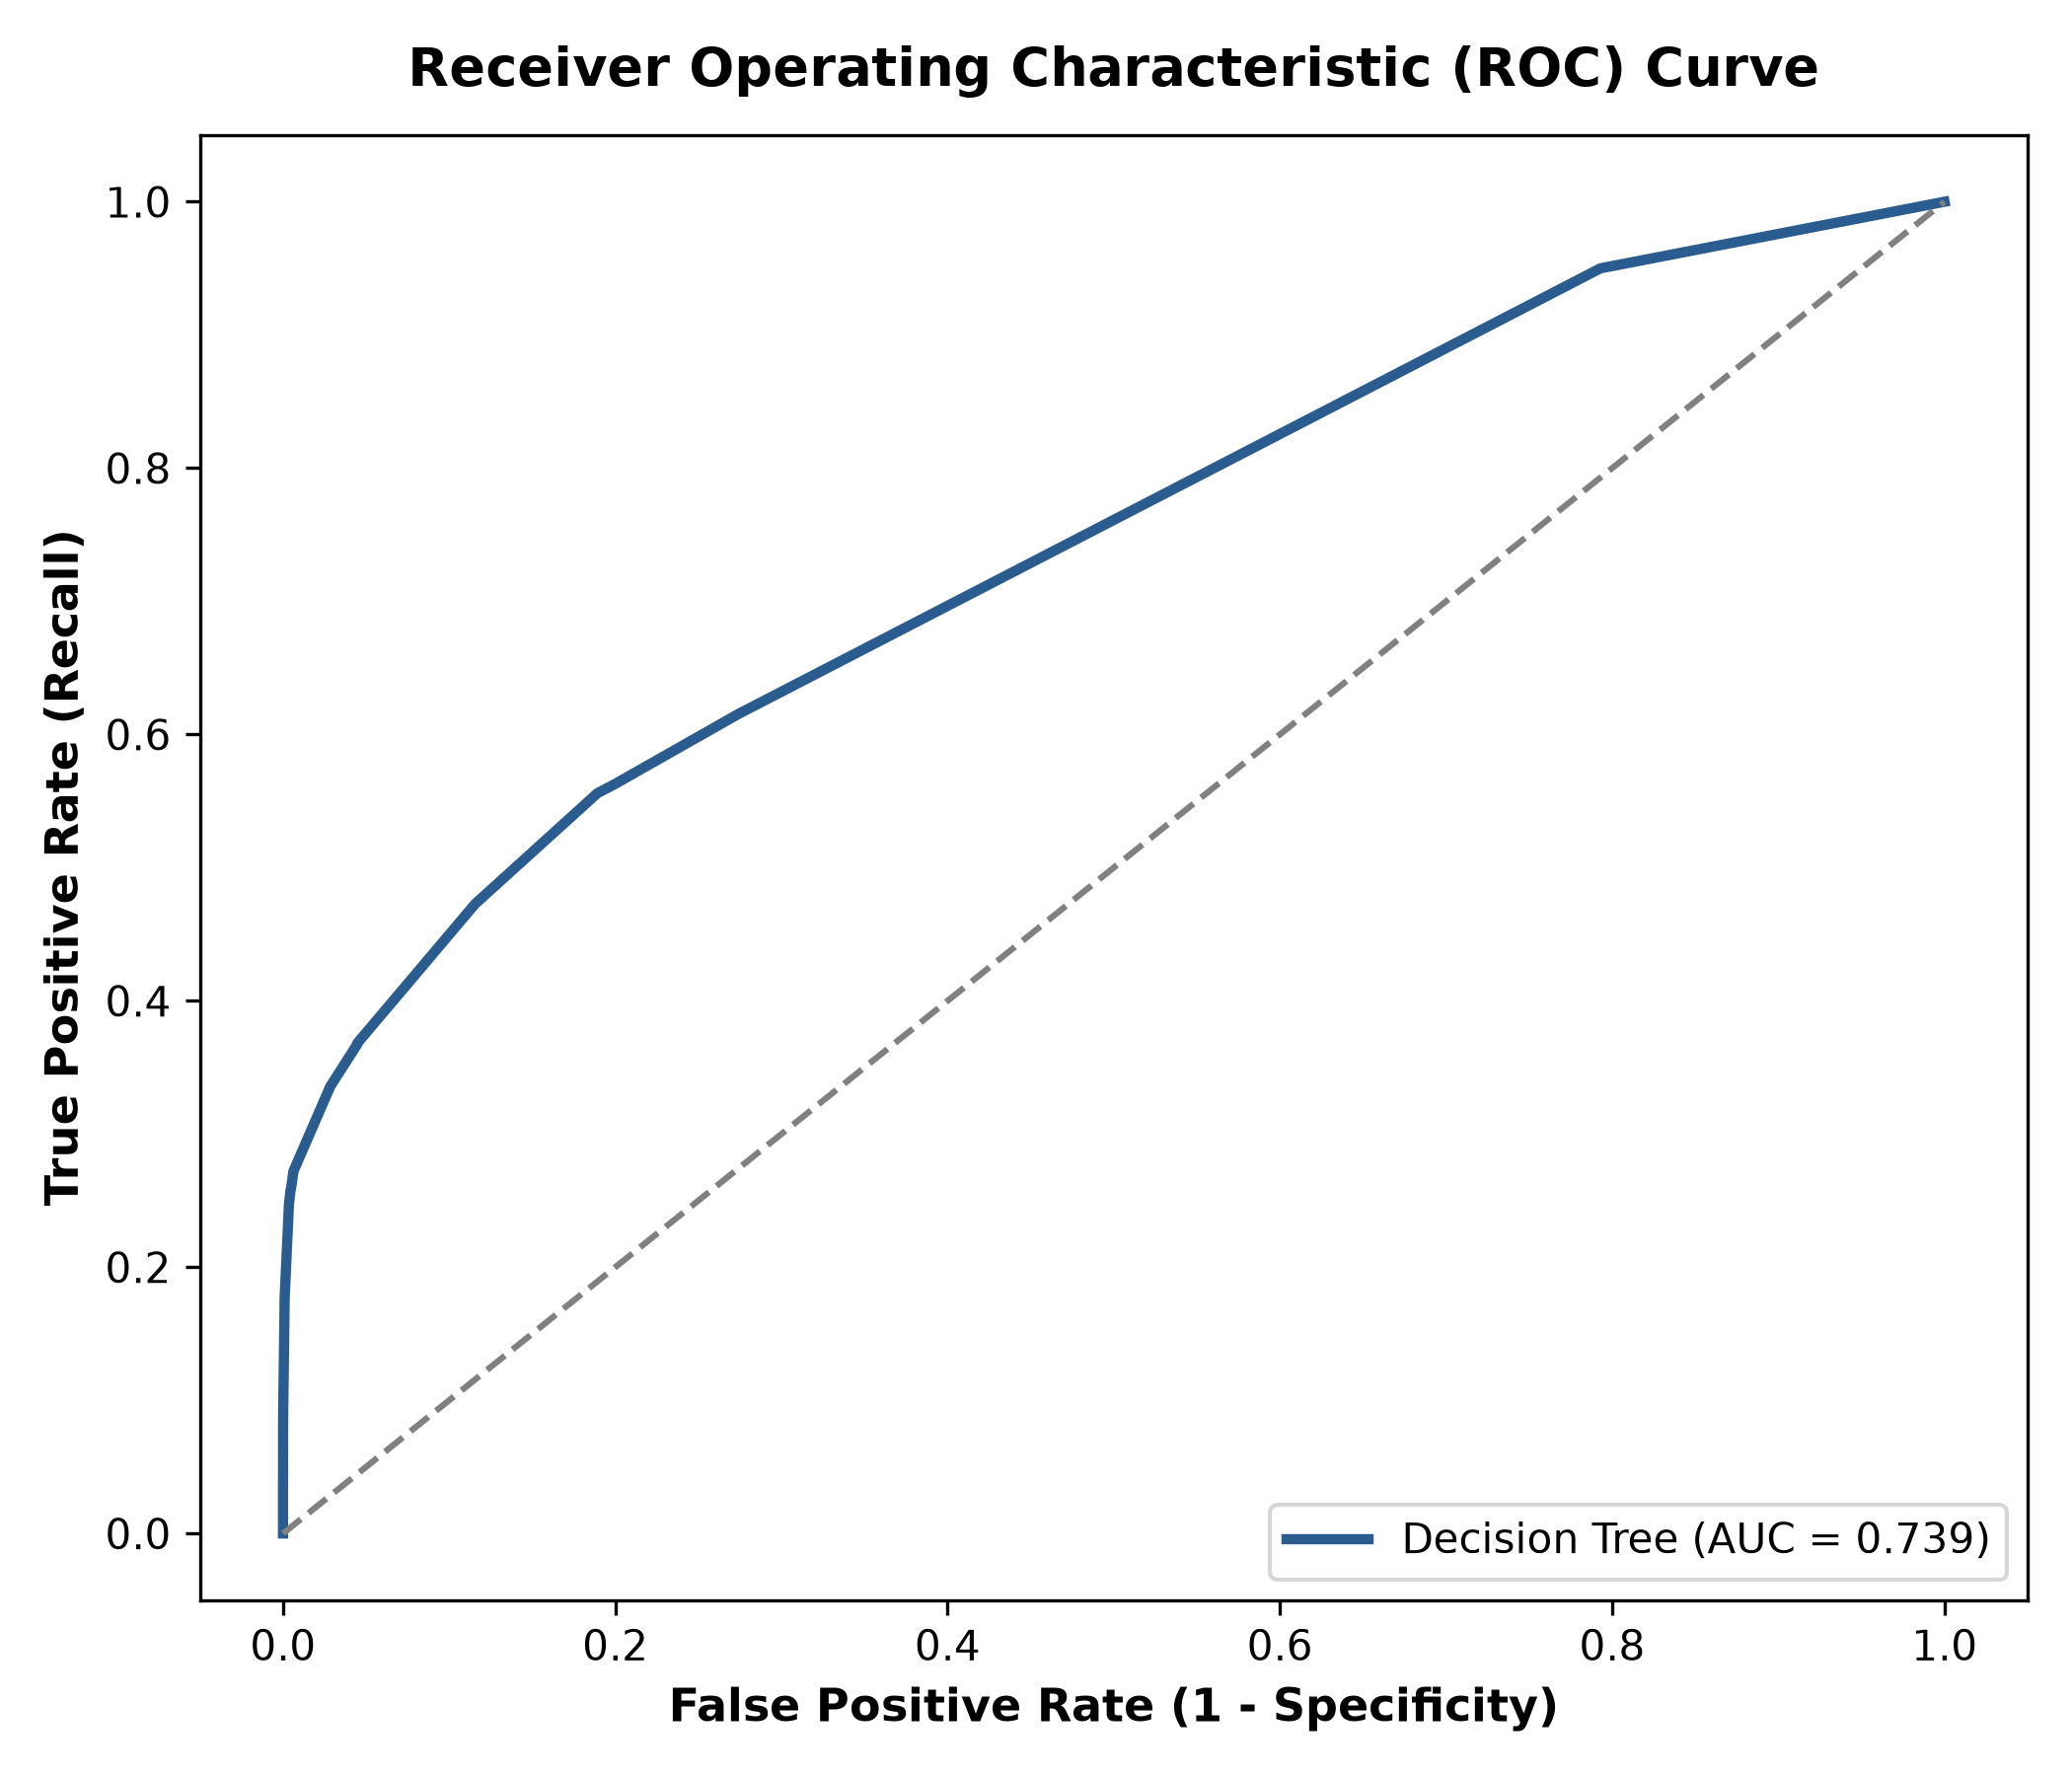

In [4]:
from IPython.display import Image, display
display(Image(filename='../outputs/figures/fig12_decision_tree_structure.png'))
display(Image(filename='../outputs/figures/fig13_confusion_matrix.png'))
display(Image(filename='../outputs/figures/fig14_roc_curve.png'))

### 4. Verbalized Decision Tree Decision Paths

In [5]:
with open('../outputs/tables/decision_tree_paths.md', 'r', encoding='utf-8') as f:
    print(f.read())

# Decision Tree Interpretation: Verbalized Decision Paths

The trained Decision Tree classifier isolates three dominant evidentiary paths determining arrest likelihood:

### Decision Path 1: Proactive Narcotics Enforcement (High Arrest Probability)
- **Path Logic:** `[PrimaryType_NARCOTICS > 0.5]`
- **Node Evaluation:** If the incident is classified as a Narcotics offense, the tree immediately routes to a leaf node predicting **Arrest Made = 1** with **>96% posterior arrest probability**.
- **Contextual Interpretation:** Narcotics violations in Chicago are predominantly proactive, officer-initiated operations (e.g. observation of street-level drug sales or contraband recovery during investigatory stops). Because detection occurs simultaneously with police apprehension, the arrest rate is nearly deterministic.

### Decision Path 2: Proactive Weapons & Concealed Carry Violations (High Arrest Probability)
- **Path Logic:** `[PrimaryType_NARCOTICS <= 0.5] -> [PrimaryType_WEAPONS VIOLATION 